# Análisis de portafolio: acciones, cripto y oro (2020 - 2026)

**Pregunta:** si en enero de 2020 hubiera invertido en alguno de estos 8 activos, ¿cuál me habría dado el mejor retorno *por unidad de riesgo*? ¿Conviene diversificar?

**Activos:** S&P 500, Apple, Microsoft, Amazon, NVIDIA, MercadoLibre, Bitcoin y Oro (futuros).
**Fuente:** Yahoo Finance (`yfinance`), precios de cierre diarios desde el 01/01/2020.
**Pipeline:** `src/main.py` descarga, limpia, calcula métricas y genera los reportes que se usan acá.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..").resolve() / "src"))
from config import DIR_PROCESSED, DIR_REPORTS

pd.set_option("display.width", 140)

## 1. Carga de datos procesados
Unifico los precios de cierre y los retornos diarios de todos los activos en dos tablas.

In [2]:
precios, retornos = {}, {}
for archivo in sorted(DIR_PROCESSED.glob("*_procesado.csv")):
    nombre = archivo.stem.replace("_procesado", "").upper()
    df = pd.read_csv(archivo, parse_dates=["Date"]).set_index("Date")
    precios[nombre] = df["Close"]
    retornos[nombre] = df["Retorno_Diario"]

df_precios = pd.DataFrame(precios)
df_retornos = pd.DataFrame(retornos)
print("Período:", df_precios.index.min().date(), "->", df_precios.index.max().date())
df_precios.tail()

Período: 2020-01-01 -> 2026-10-18


,AMAZON,APPLE,BITCOIN,GOLD,MERCADOLIBRE,MICROSOFT,NVIDIA,SP500
Date,,,,,,,,
2026-10-14,254.080002,342.959991,81562.492188,4107.899902,1839.109985,533.690002,221.300003,7718.939941
2026-10-15,254.759995,342.000000,82141.460938,4170.100098,1856.979980,539.440002,217.229996,7744.060059
2026-10-16,250.000000,343.459991,81500.804688,4181.100098,1834.000000,529.049988,214.130005,7659.439941
2026-10-17,NaN,NaN,81382.148438,NaN,NaN,NaN,NaN,NaN
2026-10-18,NaN,NaN,81656.976562,4199.399902,NaN,NaN,NaN,NaN


**Nota de calidad de datos:** Bitcoin opera 365 días al año y las acciones ~252 ruedas. Por eso la tabla unificada tiene NaN en fines de semana para las acciones. Para comparar retornos día a día uso solo las fechas en que operaron **todos** los activos (`dropna`).

In [3]:
print("Valores nulos por activo (tabla unificada):")
print(df_precios.isna().sum())

Valores nulos por activo (tabla unificada):
AMAZON          776
APPLE           776
BITCOIN           0
GOLD            772
MERCADOLIBRE    776
MICROSOFT       776
NVIDIA          776
SP500           776
dtype: int64


## 2. Ranking riesgo / retorno

In [4]:
resumen = pd.read_csv(DIR_REPORTS / "resumen_comparativo.csv")
resumen

,Ranking,Activo,Desde,Hasta,Dias_Operados,Retorno_Total_%,Retorno_Anualizado_%,Volatilidad_Anual_%,Max_Drawdown_%,Ratio_Retorno_Riesgo
0,1,NVIDIA,2020-01-02,2026-10-16,1707,3494.51,69.51,51.61,-66.34,1.35
1,2,GOLD,2020-01-02,2026-10-18,1711,175.46,16.09,19.11,-24.94,0.84
2,3,APPLE,2020-01-02,2026-10-16,1707,375.24,25.82,31.19,-33.36,0.83
3,4,BITCOIN,2020-01-01,2026-10-18,2483,1034.10,42.96,59.34,-76.63,0.72
4,5,SP500,2020-01-02,2026-10-16,1707,135.11,13.42,20.16,-33.92,0.67
5,6,MICROSOFT,2020-01-02,2026-10-16,1707,249.11,20.23,30.30,-37.15,0.67
6,7,AMAZON,2020-01-02,2026-10-16,1707,163.43,15.34,35.56,-56.15,0.43
7,8,MERCADOLIBRE,2020-01-02,2026-10-16,1707,200.56,17.60,50.48,-69.12,0.35


**Lectura:**
- **NVIDIA** lidera en retorno absoluto *y* en retorno por unidad de riesgo, impulsada por el boom de la IA (2023-2024).
- **Oro** queda 2° en el ranking pese a tener el menor retorno de los activos de riesgo: su volatilidad es la más baja (~19%) y su peor caída fue de solo -25%.
- **Bitcoin** rindió muchísimo (+1.000%), pero con la volatilidad más alta y una caída máxima de -77%: muy pocos inversores aguantan eso sin vender.
- **MercadoLibre** es el caso opuesto a NVIDIA: volatilidad similar (~50%) pero un retorno anual 4 veces menor, por eso queda último.

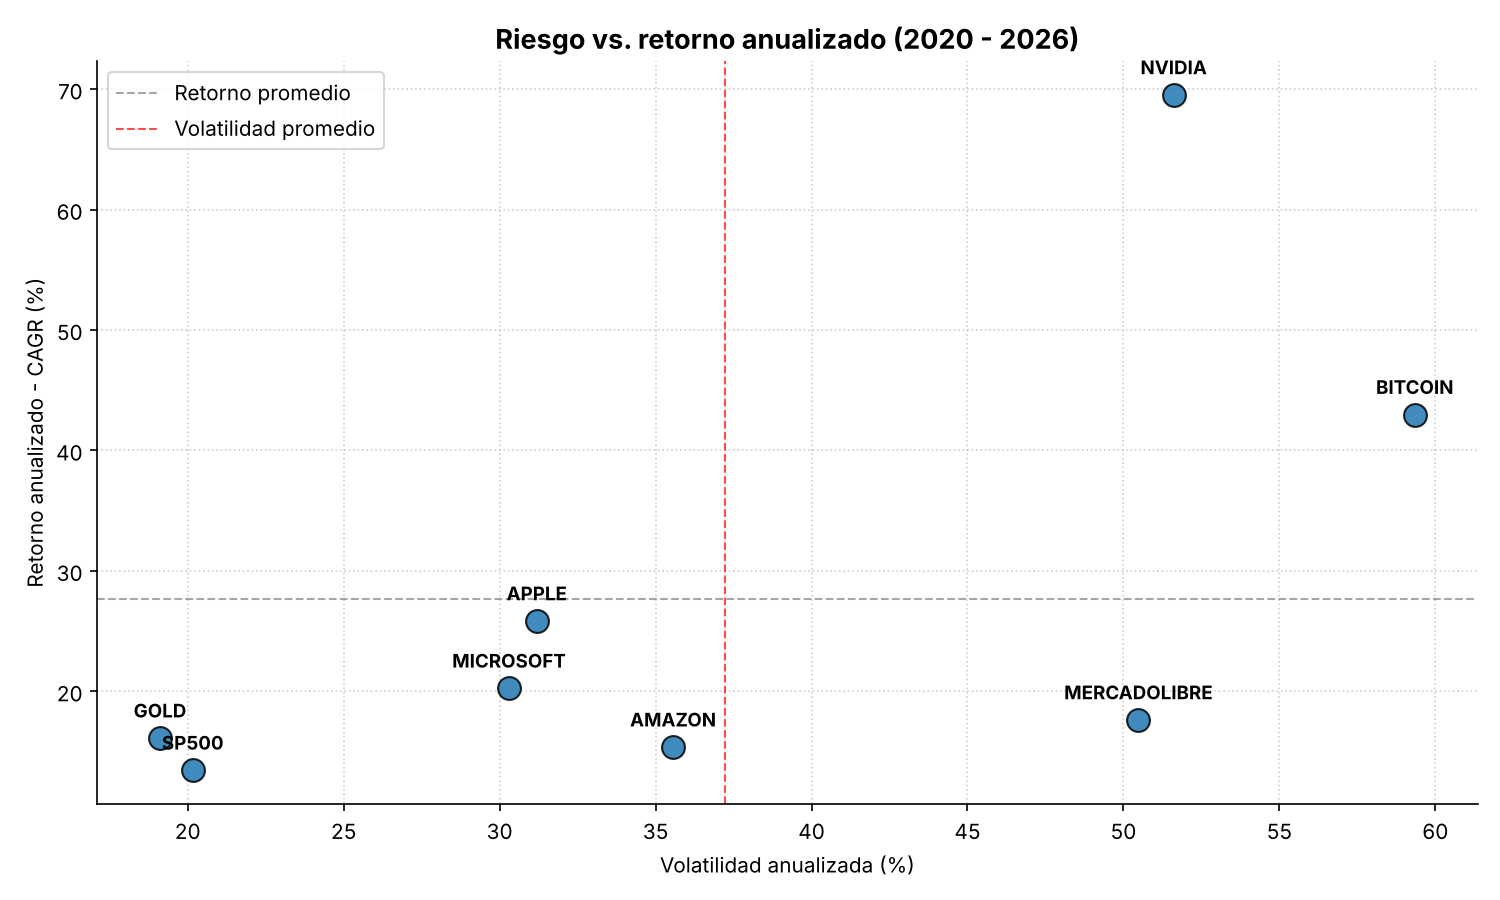

In [5]:
from IPython.display import Image
Image(DIR_REPORTS / "figures" / "mapa_riesgo_retorno.png")

## 3. Retorno por año calendario
El promedio de 6 años esconde años muy distintos.

In [6]:
cierres_anuales = df_precios.resample("YE").last()
cierres_anuales.loc[pd.Timestamp("2019-12-31")] = df_precios.bfill().iloc[0]
retorno_anual = cierres_anuales.sort_index().pct_change().dropna(how="all") * 100
retorno_anual.index = retorno_anual.index.year
retorno_anual = retorno_anual.rename(index={retorno_anual.index[-1]: f"{retorno_anual.index[-1]} (YTD)"})
retorno_anual.round(1)

,AMAZON,APPLE,BITCOIN,GOLD,MERCADOLIBRE,MICROSOFT,NVIDIA,SP500
Date,,,,,,,,
2020,71.6,78.2,302.8,24.3,174.5,39.9,118.0,15.3
2021,2.4,34.6,59.7,-3.5,-19.5,52.5,125.5,26.9
2022,-49.6,-26.4,-64.3,-0.1,-37.2,-28.0,-50.3,-19.4
2023,80.9,49.0,155.4,13.4,85.7,58.2,239.0,24.2
2024,44.4,30.7,121.1,27.5,8.2,12.9,171.2,23.3
2025,5.2,9.1,-6.3,64.4,18.5,15.6,38.9,16.4
2026 (YTD),8.3,26.7,-6.7,-3.3,-8.9,10.1,15.1,11.9


**Lectura:** 2022 fue el año de las tasas altas de la Fed: todos los activos de riesgo cayeron (Bitcoin -64%, Amazon -50%, NVIDIA -50%) y el **oro fue el único que quedó prácticamente neutro**. Ese año explica casi todos los drawdowns máximos de la tabla anterior. En 2025 el oro fue el mejor activo del grupo (+64%).

## 4. Correlaciones: ¿sirve diversificar?

In [7]:
corr = pd.read_csv(DIR_REPORTS / "matriz_correlacion.csv", index_col=0)
corr

,AMAZON,APPLE,BITCOIN,GOLD,MERCADOLIBRE,MICROSOFT,NVIDIA,SP500
AMAZON,1.00,0.54,0.28,0.06,0.49,0.63,0.55,0.64
APPLE,0.54,1.00,0.27,0.07,0.46,0.64,0.54,0.75
BITCOIN,0.28,0.27,1.00,0.12,0.28,0.31,0.32,0.38
GOLD,0.06,0.07,0.12,1.00,0.07,0.07,0.09,0.12
MERCADOLIBRE,0.49,0.46,0.28,0.07,1.00,0.49,0.50,0.54
MICROSOFT,0.63,0.64,0.31,0.07,0.49,1.00,0.62,0.76
NVIDIA,0.55,0.54,0.32,0.09,0.50,0.62,1.00,0.70
SP500,0.64,0.75,0.38,0.12,0.54,0.76,0.70,1.00


**Lectura:**
- Las acciones tecnológicas se mueven bastante juntas (0,5 - 0,76 con el S&P 500): tener 4 tecnológicas **no** es tan diversificado como parece.
- **Bitcoin** tiene correlación baja-moderada (~0,3) con las acciones.
- **El oro prácticamente no se correlaciona con nada** (≈0,1): es el mejor diversificador del grupo.

## 5. Simulación: cartera equiponderada vs. S&P 500
Reparto USD 100 en partes iguales entre los 7 activos (sin el índice) y rebalanceo diario. Lo comparo contra comprar solo el S&P 500.

In [8]:
# Retornos calculados sobre precios de fechas comunes (así no se pierden
# los movimientos de Bitcoin del fin de semana)
r = df_precios.dropna().pct_change().dropna()

def metricas(serie: pd.Series, base_anual: int = 252) -> dict:
    valor = (1 + serie).cumprod()
    anios = (serie.index[-1] - serie.index[0]).days / 365.25
    return {
        "Retorno_Total_%": (valor.iloc[-1] - 1) * 100,
        "CAGR_%": (valor.iloc[-1] ** (1 / anios) - 1) * 100,
        "Volatilidad_%": serie.std() * np.sqrt(base_anual) * 100,
        "Max_Drawdown_%": (valor / valor.cummax() - 1).min() * 100,
    }

cartera = r.drop(columns="SP500").mean(axis=1)
cartera_sin_ganadores = r.drop(columns=["SP500", "NVIDIA", "BITCOIN"]).mean(axis=1)

comparacion = pd.DataFrame({
    "Cartera equiponderada (7)": metricas(cartera),
    "Cartera sin NVIDIA ni BTC (5)": metricas(cartera_sin_ganadores),
    "Solo S&P 500": metricas(r["SP500"]),
}).T.round(2)
comparacion

,Retorno_Total_%,CAGR_%,Volatilidad_%,Max_Drawdown_%
Cartera equiponderada (7),672.31,35.16,27.42,-41.42
Cartera sin NVIDIA ni BTC (5),299.83,22.66,24.41,-31.03
Solo S&P 500,135.11,13.43,20.16,-33.92


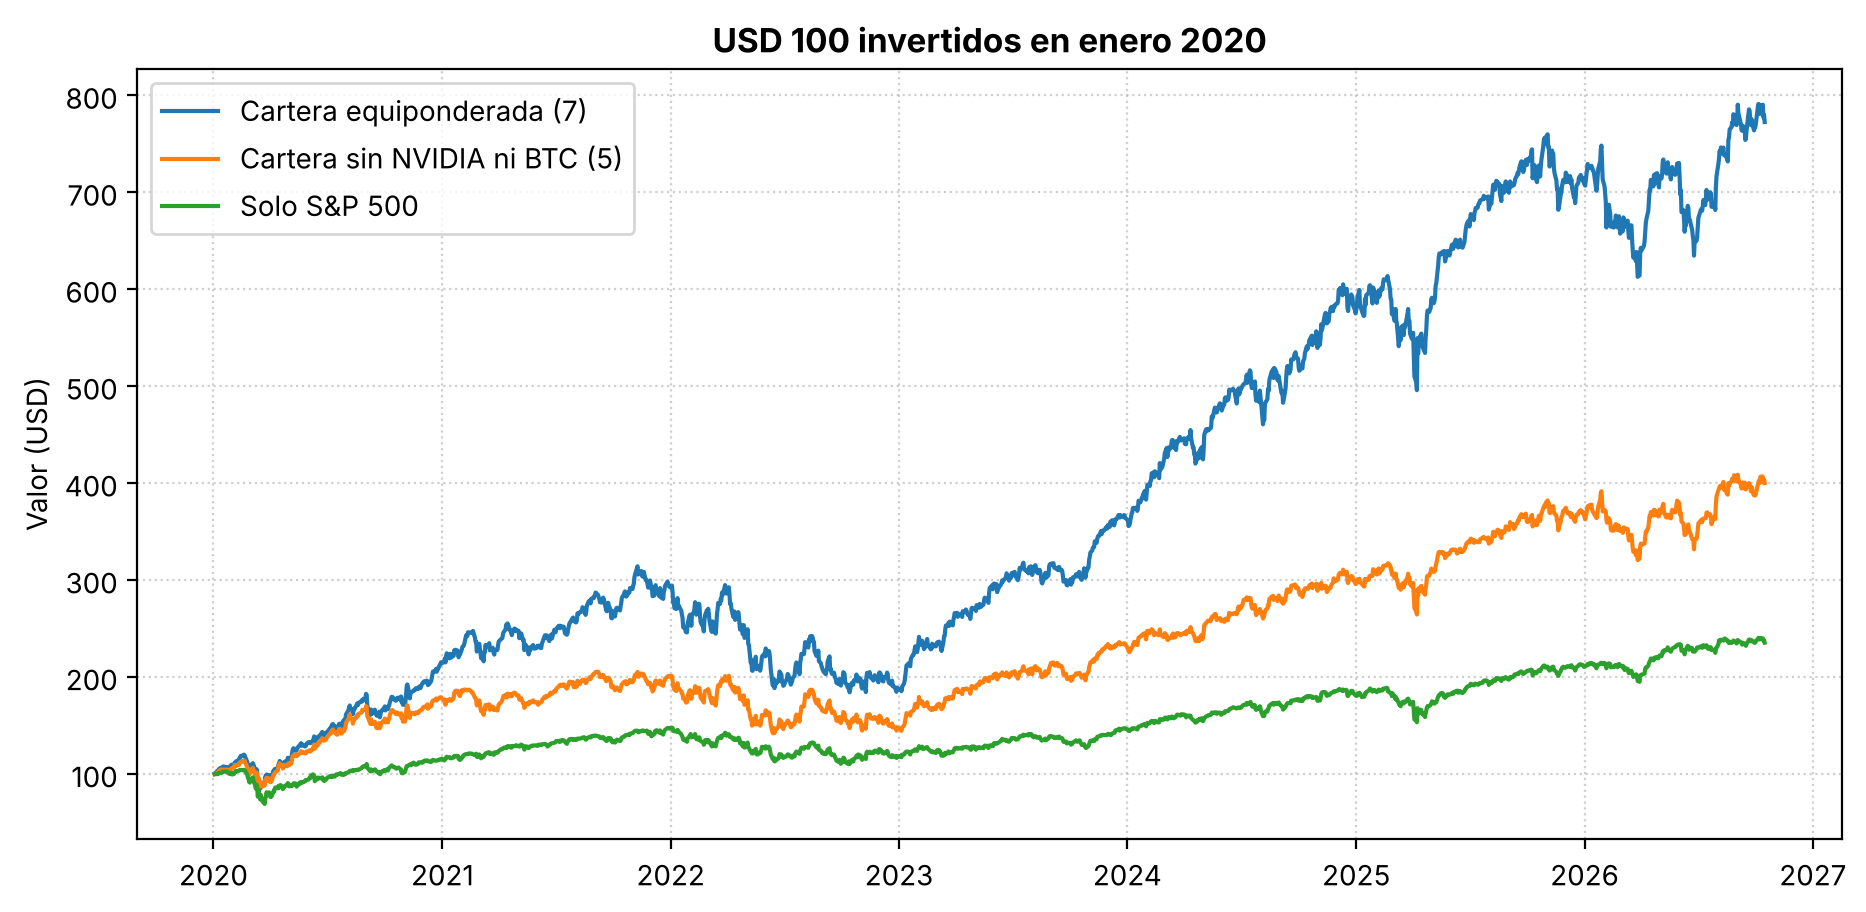

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
for nombre, serie in [("Cartera equiponderada (7)", cartera),
                      ("Cartera sin NVIDIA ni BTC (5)", cartera_sin_ganadores),
                      ("Solo S&P 500", r["SP500"])]:
    ax.plot(100 * (1 + serie).cumprod(), label=nombre, linewidth=1.5)
ax.set_title("USD 100 invertidos en enero 2020", fontweight="bold")
ax.set_ylabel("Valor (USD)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.show()

**Lectura:** la cartera equiponderada le gana al S&P 500 con un riesgo moderadamente mayor. Pero ojo con el **sesgo de selección**: elegí estos activos en 2026 sabiendo que les fue bien. Si saco a los dos grandes ganadores (NVIDIA y Bitcoin), la ventaja se reduce mucho, aunque sigue por encima del índice. Esto muestra que gran parte del resultado depende de haber "acertado" 1 o 2 activos, algo que no se sabe de antemano.

## 6. Conclusiones

1. **Retorno alto ≠ buena inversión.** Bitcoin y MercadoLibre rindieron mucho, pero con caídas de -70% o más. Medido como retorno por unidad de riesgo, NVIDIA, oro y Apple fueron más eficientes.
2. **El oro es el gran diversificador:** correlación ≈0,1 con todo y fue el único activo que no cayó fuerte en 2022.
3. **Cuatro tecnológicas no son una cartera diversificada:** se correlacionan 0,5-0,75 entre sí.
4. **Los resultados del pasado tienen sesgo de selección:** buena parte del rendimiento de la cartera viene de dos activos que hoy sabemos que fueron ganadores.

**Limitaciones:** no incluye dividendos, comisiones ni impuestos. El oro está medido con futuros (`GC=F`). La tasa libre de riesgo no se descuenta en el ratio retorno/riesgo (no es un Sharpe estricto).

**Próximos pasos posibles:** agregar el ratio de Sharpe con tasa libre de riesgo, simular carteras con distintos pesos (frontera eficiente) y medir en pesos argentinos (CEDEARs).